# NHÓM 10 — STAGE 1 + STAGE 2: PHÂN TÍCH DỮ LIỆU PHIM IMDb VÀ DỰ ĐOÁN `rating_2026`

- **Stage 1:** xác định câu hỏi, nạp và gộp dữ liệu, dữ liệu thiếu, data wrangling, EDA, trực quan hóa.
- **Stage 2:** PCA, K-Means, hồi quy, phân loại, đánh giá mô hình, lưu mô hình cho giao diện Streamlit.

Chạy các cell theo thứ tự từ trên xuống dưới. Cần Internet để tải dữ liệu bằng `kagglehub`. Kết quả phụ thuộc phiên bản dữ liệu tải về, không ghi số liệu vào nhận xét trước khi chạy.

## 0. Xác định câu hỏi phân tích (Stage 1, bước 1)


| Nội dung | Mô tả |
|---|---|
| **Muốn biết gì** | Những thuộc tính nào của phim (năm, thứ hạng và điểm ở bảng cũ, lượt vote, thời lượng, metascore, ngân sách, doanh thu) đi cùng với `rating_2026`, và có thể dự đoán `rating_2026` tốt đến mức nào |
| **Cho ai** | Người cần ước lượng điểm IMDb của phim Top 250  |
| **Đo thành công thế nào** | Hồi quy: MAE, RMSE, R² trên tập test. Phân loại nhóm rating: Accuracy, F1-macro. Phân cụm: Silhouette. So với baseline đơn giản `ŷ = rating_v1` |

## 1. Cấu hình

In [1]:


import os, re, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
SEED = RANDOM_STATE
N_TREES = 300

## 2. Nạp dữ liệu và gộp 3 bảng (Stage 1: data loading)

Ba bộ dữ liệu Top 250 IMDb ở ba thời điểm khác nhau:

| Biến | Nguồn (Kaggle) | Ý nghĩa |
|---|---|---|
| `df1` | `ashishjangra27/imdb-top-250-movies` | danh sách cũ (hậu tố `_v1`) |
| `df5` | `rajugc/imdb-top-250-movies-dataset` | có `box_office`, `tagline` |
| `df6` | `arjunsinghgangwar/top-250-movies-on-imdb-in-2026` | danh sách 2026 (chứa `rating_2026`, là biến mục tiêu) |

In [2]:
import kagglehub
from pathlib import Path

def find_csv(dataset_path, expected_name):
    root = Path(dataset_path)
    expected = expected_name.lower()
    for file_path in root.rglob("*.csv"):
        if file_path.name.lower() == expected:
            return str(file_path)
    csv_files = list(root.rglob("*.csv"))
    if len(csv_files) == 1:
        return str(csv_files[0])
    available = [str(p.name) for p in csv_files]
    raise FileNotFoundError(
        f"Khong tim thay {expected_name} trong {root}. Cac file CSV hien co: {available}"
    )

path1 = kagglehub.dataset_download("ashishjangra27/imdb-top-250-movies")
path5 = kagglehub.dataset_download("rajugc/imdb-top-250-movies-dataset")
path6 = kagglehub.dataset_download("arjunsinghgangwar/top-250-movies-on-imdb-in-2026")

df1 = pd.read_csv(find_csv(path1, "movies.csv"))
df5 = pd.read_csv(find_csv(path5, "IMDB Top 250 Movies.csv"))
df6 = pd.read_csv(find_csv(path6, "ToP 250 movies on imdb in 2026.csv"))

if "certificate" in df1.columns:
    df1 = df1.drop(columns=["certificate"])
df6 = df6.drop(columns=[
    c for c in ["url", "id", "originalTitle", "type", "primaryImage", "thumbnails", "trailer"]
    if c in df6.columns
])

print("df1:", df1.shape, "| df5:", df5.shape, "| df6:", df6.shape)
print("Cột df1:", df1.columns.tolist())
print("Cột df5:", df5.columns.tolist())
print("Cột df6:", df6.columns.tolist())

df1: (250, 15) | df5: (250, 13) | df6: (250, 20)
Cột df1: ['rank', 'id', 'name', 'year', 'imbd_votes', 'imdb_rating', 'duration', 'genre', 'cast_id', 'cast_name', 'director_id', 'director_name', 'writter_name', 'writter_id', 'img_link']
Cột df5: ['rank', 'name', 'year', 'rating', 'genre', 'certificate', 'run_time', 'tagline', 'budget', 'box_office', 'casts', 'directors', 'writers']
Cột df6: ['primaryTitle', 'description', 'contentRating', 'startYear', 'endYear', 'releaseDate', 'interests', 'countriesOfOrigin', 'externalLinks', 'spokenLanguages', 'filmingLocations', 'productionCompanies', 'budget', 'grossWorldwide', 'genres', 'isAdult', 'runtimeMinutes', 'averageRating', 'numVotes', 'metascore']


### Chuẩn hóa khóa ghép và gộp (outer join)
Khóa ghép là `title_key` (tên phim viết thường, bỏ ký tự đặc biệt) cùng với `year`. Outer join giữ cả phim chỉ xuất hiện ở một bảng, nên số dòng sau gộp lớn hơn 250.

In [3]:
def create_title_key(series):
    return (series.astype(str).str.strip().str.lower()
            .str.replace(r"[^\w\s]", "", regex=True))

def parse_runtime_to_minutes(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().lower()
    hours = re.search(r"(\d+)\s*h", val)
    mins = re.search(r"(\d+)\s*m", val)
    if hours or mins:
        return (int(hours.group(1)) if hours else 0) * 60 + (int(mins.group(1)) if mins else 0)
    num = re.search(r"\d+", val)
    return int(num.group(0)) if num else np.nan

df1_prep = df1.copy()
df1_prep["title_key"] = create_title_key(df1_prep["name"])
df1_prep["runtime_v1"] = pd.to_numeric(df1_prep["duration"], errors="coerce")
df1_prep = df1_prep.rename(columns={
    "name":"movie_name", "imdb_rating":"rating_v1", "rank":"rank_v1",
    "imbd_votes":"votes_v1", "genre":"genre_v1"
})

df5_prep = df5.copy()
df5_prep["title_key"] = create_title_key(df5_prep["name"])
df5_prep["runtime_v5"] = df5_prep["run_time"].apply(parse_runtime_to_minutes)
df5_prep["budget_v5"] = pd.to_numeric(df5_prep["budget"], errors="coerce")
df5_prep["box_office_v5"] = pd.to_numeric(df5_prep["box_office"], errors="coerce")
df5_prep = df5_prep.rename(columns={
    "name":"movie_name", "rating":"rating_v5", "rank":"rank_v5", "genre":"genre_v5"
})

df6_prep = df6.copy()
df6_prep["title_key"] = create_title_key(df6_prep["primaryTitle"])

# Chuan hoa nam ve cung kieu so truoc khi merge cac bo du lieu.
for frame, year_col in [(df1_prep, "year"), (df5_prep, "year"), (df6_prep, "startYear")]:
    if year_col in frame.columns:
        frame[year_col] = pd.to_numeric(frame[year_col], errors="coerce").astype("Int64")
df6_prep = df6_prep.rename(columns={
    "primaryTitle":"movie_name", "averageRating":"rating_2026",
    "numVotes":"votes_2026", "runtimeMinutes":"runtime_2026",
    "startYear":"year", "genres":"genre_2026"
})

cols_df1 = ["title_key","year","movie_name","rank_v1","rating_v1","votes_v1",
            "runtime_v1","genre_v1","director_name"]
cols_df6 = ["title_key","year","movie_name","rating_2026","votes_2026","runtime_2026",
            "metascore","budget","contentRating","productionCompanies","genre_2026"]
merged_1_6 = pd.merge(df1_prep[cols_df1], df6_prep[cols_df6],
                      on=["title_key","year"], how="outer", suffixes=("_v1","_2026"))
cols_df5 = ["title_key","year","rank_v5","rating_v5","runtime_v5","tagline","box_office"]
df_final = pd.merge(merged_1_6, df5_prep[cols_df5],
                    on=["title_key","year"], how="outer")
df_final["movie_name"] = df_final.get("movie_name_2026", pd.Series(index=df_final.index, dtype=object)).combine_first(
    df_final.get("movie_name_v1", pd.Series(index=df_final.index, dtype=object)))
df_final = df_final.drop(columns=["movie_name_v1","movie_name_2026"], errors="ignore")
df_final = df_final.drop(columns=[c for c in ["rank_v5","rating_v5","runtime_v5"] if c in df_final.columns], errors="ignore")
df_final = df_final.rename(columns={"box_office_v5":"box_office"})
df_final = df_final.drop_duplicates(subset=["title_key","year"]).reset_index(drop=True)
for col in df_final.columns:
    if col in ["year","rank_v1","rating_v1","votes_v1","runtime_v1","rating_2026",
               "votes_2026","runtime_2026","metascore","budget","box_office"]:
        df_final[col] = pd.to_numeric(df_final[col], errors="coerce")
print("Dataset sau gộp:", df_final.shape)
display(df_final.head())

Dataset sau gộp: (317, 19)


,title_key,year,rank_v1,rating_v1,votes_v1,runtime_v1,genre_v1,director_name,rating_2026,votes_2026,runtime_2026,metascore,budget,contentRating,productionCompanies,genre_2026,tagline,box_office,movie_name
0,12 angry men,1957,5.0,9.0,768548.0,96.0,"Crime,Drama",Sidney Lumet,9.0,996035.0,96.0,97.0,350000.0,Approved,"[{'id': 'co0032902', 'name': 'Orion-Nova Produ...","['Crime', 'Drama']",Life Is In Their Hands -- Death Is On Their Mi...,955.0,12 Angry Men
1,12 years a slave,2013,182.0,8.1,688749.0,134.0,"Biography,Drama,History",Steve McQueen,8.1,791703.0,134.0,96.0,20000000.0,R,"[{'id': 'co0172093', 'name': 'Regency Enterpri...","['Biography', 'Drama', 'History']",The extraordinary true story of Solomon Northup,187733202.0,12 Years a Slave
2,12th fail,2023,NaN,NaN,NaN,NaN,NaN,NaN,8.7,175242.0,147.0,NaN,NaN,NaN,"[{'id': 'co0774661', 'name': 'Vinod Chopra Fil...","['Biography', 'Drama']",NaN,NaN,12th Fail
3,1917,2019,122.0,8.2,556620.0,119.0,"Action,Drama,War",Sam Mendes,8.2,780477.0,119.0,78.0,95000000.0,R,"[{'id': 'co0819670', 'name': 'DreamWorks Pictu...","['Drama', 'War']",Time is the enemy.,384479940.0,1917
4,2001 a space odyssey,1968,89.0,8.3,654705.0,149.0,"Adventure,Sci-Fi",Stanley Kubrick,8.3,788945.0,149.0,84.0,12000000.0,G,"[{'id': 'co0007143', 'name': 'Metro-Goldwyn-Ma...","['Adventure', 'Sci-Fi']",Let the Awe and Mystery of a Journey Unlike An...,65889846.0,2001: A Space Odyssey


### Bảng thuộc tính của dataset

| Thuộc tính | Ý nghĩa |
|---|---|
| `movie_name`, `year`, `title_key` | tên phim, năm phát hành, khóa ghép |
| `rank_v1`, `rating_v1`, `votes_v1`, `runtime_v1`, `genre_v1` | thứ hạng, điểm, lượt vote, thời lượng, thể loại ở bảng cũ |
| `director_name` | đạo diễn |
| **`rating_2026`** | **điểm IMDb năm 2026 (biến mục tiêu)** |
| `votes_2026`, `runtime_2026`, `genre_2026` | lượt vote, thời lượng, thể loại năm 2026 |
| `metascore` | điểm từ giới phê bình |
| `budget`, `box_office` | ngân sách, doanh thu |
| `contentRating`, `productionCompanies`, `tagline` | phân loại độ tuổi, hãng sản xuất, khẩu hiệu |

## 3. Data wrangling (6 bước) và dữ liệu thiếu

| Bước wrangling | |
|---|---|
| **Discovery** | `shape`, `describe`, kiểm tra trùng, thống kê dữ liệu thiếu (mục 3.1) |
| **Structuring** | đổi tên cột, tạo `title_key`, đổi thời lượng `2h 22m` thành phút, gộp 3 bảng bằng outer join (mục 2) |
| **Cleaning** | bỏ dòng thiếu biến mục tiêu, điền `"Unknown"` cho cột chữ, quyết định về outlier, `reset_index(drop=True)` (mục 3.3 và 4.5) |
| **Enriching** | tạo biến mới: thập niên, nhóm thời lượng, log lượt vote, biến đổi rating (mục 4.6) |
| **Validating** | kiểm tra trùng khóa, biến mục tiêu không thiếu, chỉ số liên tục (mục 4.7) |
| **Publishing** | lưu `imdb_top250_clean.csv` (mục 4.7) |

### 3.1 Khám phá và dữ liệu thiếu

In [4]:
print('Số dòng:', df_final.shape[0], '| Số cột:', df_final.shape[1])
print('Dòng trùng hoàn toàn:', df_final.duplicated().sum())
display(df_final.describe().T.round(2))

Số dòng: 317 | Số cột: 19
Dòng trùng hoàn toàn: 0


,count,mean,std,min,25%,50%,75%,max
year,317.0,1987.694006,25.653196,1921.0,1966.0,1995.0,2008.0,2026.0
rank_v1,250.0,125.5,72.312977,1.0,63.25,125.5,187.75,250.0
rating_v1,250.0,8.3112,0.229445,8.0,8.1,8.25,8.4,9.3
votes_v1,250.0,620428.732,501411.723453,28680.0,209944.75,482315.0,935673.0,2601152.0
runtime_v1,249.0,128.843373,29.909062,45.0,107.0,126.0,145.0,238.0
rating_2026,250.0,8.3144,0.233088,8.0,8.1,8.2,8.4,9.3
votes_2026,250.0,770180.944,631571.765823,25791.0,251428.75,618795.5,1160524.25,3219026.0
runtime_2026,250.0,131.736,34.503744,45.0,109.25,128.5,147.75,374.0
metascore,232.0,82.702586,11.022307,55.0,75.0,85.0,91.0,100.0
budget,226.0,180986394.50885,1210412240.339303,133000.0,3300000.0,18000000.0,63000000.0,15000000000.0


,Số lượng thiếu,Tỷ lệ thiếu (%)
box_office,100,31.5
budget,91,28.7
metascore,85,26.8
contentRating,73,23.0
runtime_v1,68,21.5
rank_v1,67,21.1
rating_v1,67,21.1
votes_v1,67,21.1
genre_v1,67,21.1
runtime_2026,67,21.1


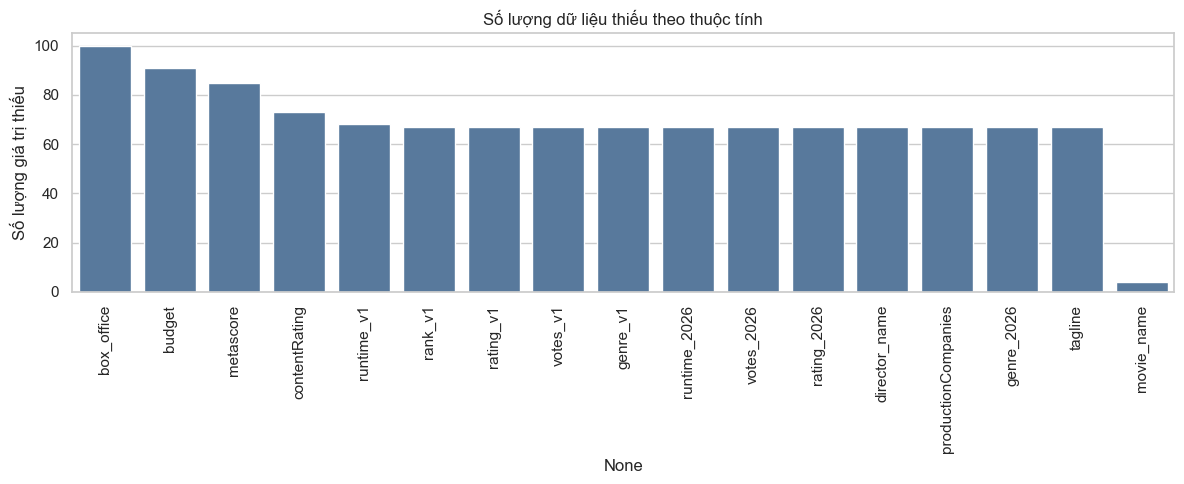

In [5]:
missing = pd.DataFrame({'Số lượng thiếu': df_final.isnull().sum(),
                        'Tỷ lệ thiếu (%)': (df_final.isnull().mean() * 100).round(1)})
missing = missing[missing['Số lượng thiếu'] > 0].sort_values('Số lượng thiếu', ascending=False)
display(missing)

plt.figure(figsize=(12, 5))
sns.barplot(x=missing.index, y=missing['Số lượng thiếu'].values, color='#4C78A8')
plt.xticks(rotation=90)
plt.ylabel('Số lượng giá trị thiếu')
plt.title('Số lượng dữ liệu thiếu theo thuộc tính')
plt.tight_layout(); plt.show()

**Nhận xét:** có 67 dòng thiếu `rating_2026` cùng lúc với toàn bộ nhóm cột của bảng 2026. Đó là những phim có trong danh sách cũ nhưng không ghép được với bảng 2026 theo `title_key` + `year`. Các dòng này **không có nhãn nên không dùng để huấn luyện**. Ở bước 3 ta loại chúng, thay vì điền giá trị cho biến mục tiêu.

### 3.2 Cơ chế thiếu dữ liệu: MCAR, MAR, MNAR

- **MCAR:** thiếu hoàn toàn ngẫu nhiên, không liên quan biến nào.
- **MAR:** việc thiếu phụ thuộc vào các cột khác **đã quan sát được**.
- **MNAR:** việc thiếu phụ thuộc vào **chính giá trị bị thiếu** (không kiểm định được từ dữ liệu quan sát, chỉ lập luận).

Cell dưới so sánh trung vị của vài cột quan sát được giữa nhóm *thiếu* và nhóm *không thiếu* của từng cột (Mann–Whitney). p-value nhỏ (< 0.05) gợi ý việc thiếu **có liên quan** đến cột so sánh, tức là không phải MCAR. Số mẫu mỗi nhóm dưới 5 thì bỏ qua.

In [6]:
from scipy import stats

cols_check = ["rating_2026", "box_office", "budget", "metascore", "contentRating", "runtime_v1"]
refs = ["year", "votes_2026", "rating_v1"]
rows = []
for c in cols_check:
    miss = df_final[c].isna()
    for ref in refs:
        if ref == c:
            continue
        a = df_final.loc[miss, ref].dropna().astype(float)
        b = df_final.loc[~miss, ref].dropna().astype(float)
        if len(a) >= 5 and len(b) >= 5:
            rows.append({"Cột thiếu": c, "Số dòng thiếu": int(miss.sum()), "So sánh theo": ref,
                         "Median khi thiếu": a.median(), "Median khi có": b.median(),
                         "p-value": stats.mannwhitneyu(a, b).pvalue})
mar_table = pd.DataFrame(rows)
display(mar_table.round(4))

,Cột thiếu,Số dòng thiếu,So sánh theo,Median khi thiếu,Median khi có,p-value
0,rating_2026,67,year,1985.0,1996.5,0.0125
1,rating_2026,67,rating_v1,8.2,8.3,0.2191
2,box_office,100,year,1999.0,1993.0,0.0175
3,box_office,100,votes_2026,206661.0,788945.0,0.0000
4,box_office,100,rating_v1,8.2,8.3,0.6676
5,budget,91,year,1985.0,1997.0,0.0124
6,budget,91,votes_2026,97371.5,748199.5,0.0000
7,budget,91,rating_v1,8.2,8.3,0.2965
8,metascore,85,year,1985.0,1997.0,0.0125
9,metascore,85,votes_2026,160887.5,717583.0,0.0000


**Kết luận :**
- Khối 67 dòng thiếu `rating_2026` kéo theo cả nhóm cột bảng 2026: do **phim không ghép được giữa các bảng** (khác tên hoặc năm), nên thiếu phụ thuộc vào nguồn dữ liệu và các cột đã quan sát, nghiêng về **MAR**.
- `box_office`, `budget`, `metascore`: nếu bảng trên cho thấy nhóm thiếu khác nhóm có về `year` thì nghiêng về MAR (phim cũ ít được ghi nhận). Khả năng **MNAR** (phim doanh thu thấp ít được công bố) không kiểm định được, chỉ nêu như giả thuyết.
- Chỉ kết luận MCAR cho cột nào mà mọi p-value đều lớn.

### 3.3 Xử lý dữ liệu thiếu theo loại cột

| Loại cột | Cách xử lý | Lý do |
|---|---|---|
| Biến mục tiêu `rating_2026` thiếu | `dropna`, rồi `reset_index(drop=True)` | không điền nhãn giả |
| Cột chữ (`genre_*`, `director_name`, `contentRating`, ...) | điền `"Unknown"` | nhiều ô trống, không có mode đủ đại diện |
| Cột số thiếu nhiều (`box_office`, `budget`, `metascore`, các cột `_v1`) | **giữ NaN**, điền **median** trong pipeline sau khi chia train/test | thiếu khá nhiều và phân phối lệch nên dùng median; điền trong pipeline để tránh rò rỉ thống kê từ test sang train |

In [7]:
df_clean = (df_final.dropna(subset=["rating_2026"])
                    .replace([np.inf, -np.inf], np.nan)
                    .reset_index(drop=True))

text_cols = [c for c in df_clean.columns
             if c != "title_key" and not pd.api.types.is_numeric_dtype(df_clean[c])]
for c in text_cols:
    df_clean[c] = df_clean[c].fillna("Unknown")

print("Trước:", df_final.shape, "| Sau khi bỏ dòng thiếu nhãn:", df_clean.shape)
print("Cột chữ đã điền 'Unknown':", text_cols)
display(df_clean.isna().sum()[lambda s: s > 0].rename("Còn thiếu (cột số, sẽ điền median trong pipeline)").to_frame())

Trước: (317, 19) | Sau khi bỏ dòng thiếu nhãn: (250, 19)
Cột chữ đã điền 'Unknown': ['genre_v1', 'director_name', 'contentRating', 'productionCompanies', 'genre_2026', 'tagline', 'movie_name']


,"Còn thiếu (cột số, sẽ điền median trong pipeline)"
rank_v1,63
rating_v1,63
votes_v1,63
runtime_v1,64
metascore,18
budget,24
box_office,51


## 4. Phân tích khám phá dữ liệu (EDA) và trực quan hóa

EDA gồm 6 bước: (1) load và kiểm tra shape, (2) dữ liệu thiếu và giá trị không hợp lệ (mục 3), (3) outlier bằng IQR, (4) phân phối, (5) quan hệ giữa các biến, (6) feature engineering và tóm tắt. EDA chỉ mô tả và gợi ý, **không kết luận nhân quả**.

Dùng Matplotlib khi cần chỉnh bố cục và Seaborn để vẽ nhanh từ DataFrame.

### 4.1 Phân phối biến mục tiêu `rating_2026`

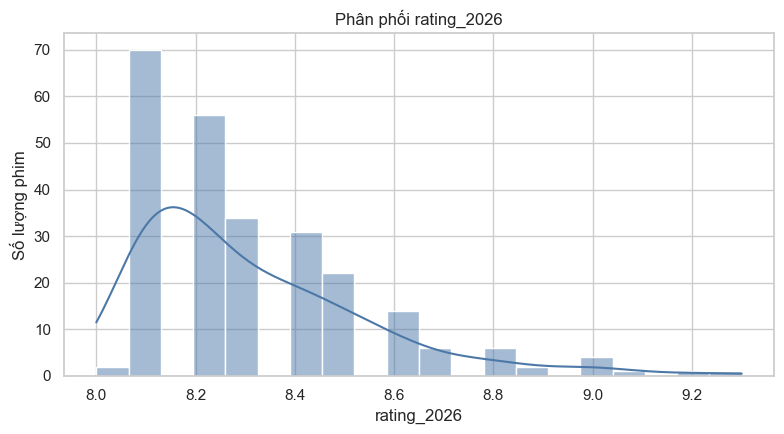

count    250.000
mean       8.314
std        0.233
min        8.000
25%        8.100
50%        8.200
75%        8.400
max        9.300
Name: rating_2026, dtype: float64


In [8]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df_clean['rating_2026'].dropna(), bins=20, kde=True, color='#4C78A8')
plt.xlabel('rating_2026'); plt.ylabel('Số lượng phim')
plt.title('Phân phối rating_2026')
plt.tight_layout(); plt.show()
print(df_clean['rating_2026'].describe().round(3))

Điểm tập trung ở 8.0–8.4 vì đây là danh sách Top 250, nên khoảng biến thiên hẹp. Điều này giới hạn mức R² có thể đạt được.

### 4.2 Tương quan giữa các biến số

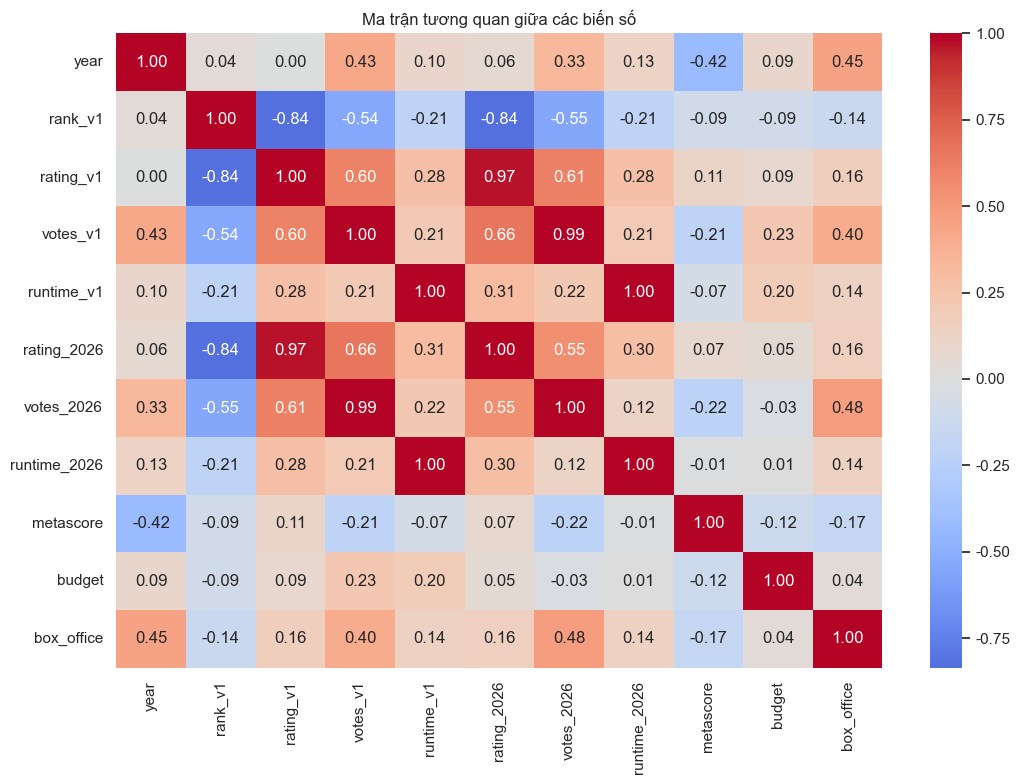

,corr với rating_2026
rating_v1,0.970
votes_v1,0.657
votes_2026,0.549
runtime_v1,0.306
runtime_2026,0.296
box_office,0.157
metascore,0.071
year,0.065
budget,0.050
rank_v1,-0.836


In [9]:
num_cols = ['year', 'rank_v1', 'rating_v1', 'votes_v1', 'runtime_v1', 'rating_2026',
            'votes_2026', 'runtime_2026', 'metascore', 'budget', 'box_office']
corr = df_clean[num_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan giữa các biến số')
plt.tight_layout(); plt.show()

display(corr['rating_2026'].drop('rating_2026').sort_values(ascending=False).round(3).to_frame('corr với rating_2026'))

`rating_v1` (≈ 0.97) và `rank_v1` (≈ −0.84) tương quan rất mạnh với `rating_2026`; metascore, year, budget gần như không tương quan tuyến tính. Ta sẽ so sánh với kết quả Feature Importance ở Biểu đồ 6.

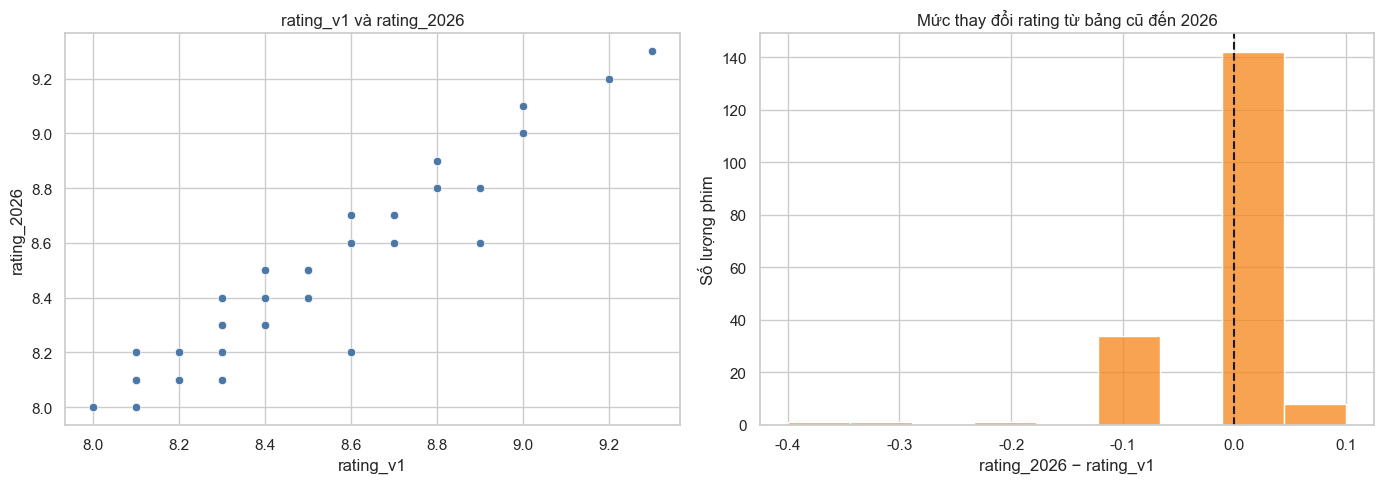

Số phim có cả hai điểm: 187 | thay đổi trung bình = -0.0187 | độ lệch chuẩn = 0.0589
Tỷ lệ phim không đổi điểm: 75.9%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df_clean, x='rating_v1', y='rating_2026', ax=axes[0], color='#4C78A8')
axes[0].set_title('rating_v1 và rating_2026')

change = (df_clean['rating_2026'] - df_clean['rating_v1']).dropna()
sns.histplot(change, kde=False, ax=axes[1], color='#F58518')
axes[1].axvline(0, linestyle='--', color='k')
axes[1].set_xlabel('rating_2026 − rating_v1'); axes[1].set_ylabel('Số lượng phim')
axes[1].set_title('Mức thay đổi rating từ bảng cũ đến 2026')
plt.tight_layout(); plt.show()

print(f'Số phim có cả hai điểm: {len(change)} | thay đổi trung bình = {change.mean():.4f} | độ lệch chuẩn = {change.std():.4f}')
print(f'Tỷ lệ phim không đổi điểm: {(change == 0).mean():.1%}')

Phần lớn phim giữ nguyên điểm. Nên bài toán thực chất là dự đoán một **độ trôi nhỏ** quanh `rating_v1`. Điều này giải thích vì sao `rating_v1` chiếm vị trí cao nhất ở Biểu đồ 6.

### 4.3 Biến phân loại và quan hệ theo nhóm

Khi số phim mỗi nhóm khác nhau nhiều, so sánh theo **tỷ lệ** thay vì theo số lượng. Ở đây "rating cao" là rating ≥ trung vị của `rating_2026`.

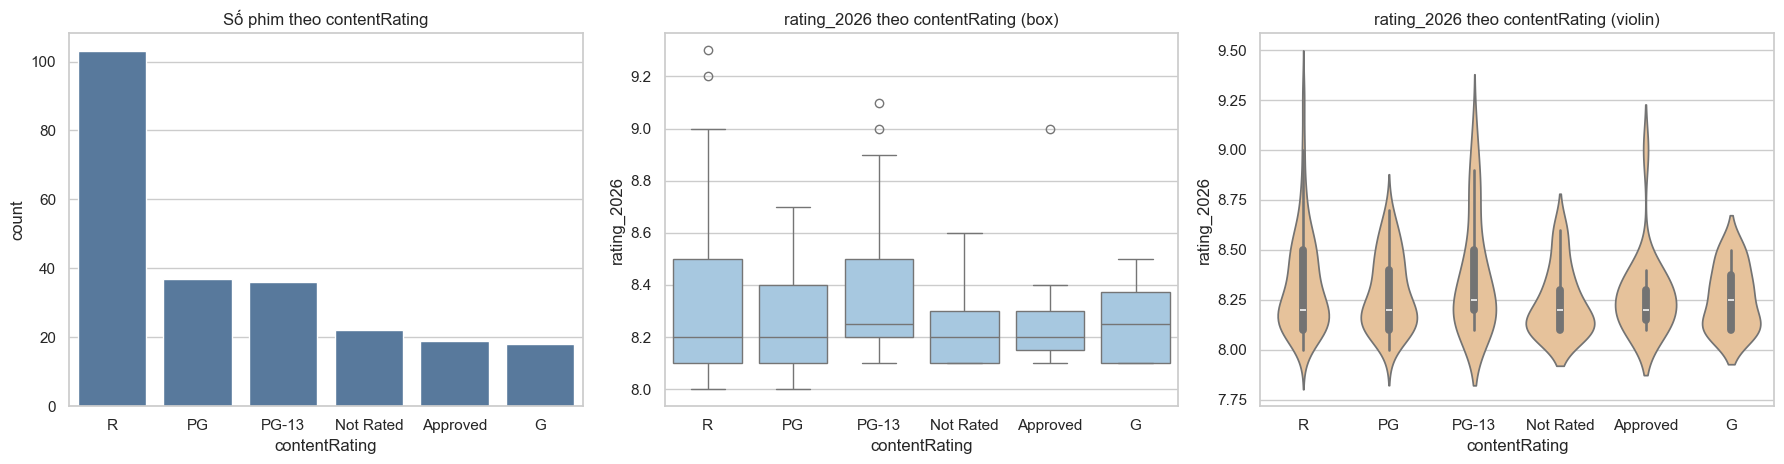

,So_phim,Ty_le_rating_cao
contentRating,,
R,103,0.728
PG,37,0.703
PG-13,36,0.778
Not Rated,22,0.545
Approved,19,0.737
G,18,0.611


,So_phim,Ty_le_rating_cao
genre,,
['Drama'],15,0.867
['Crime',36,0.806
['Drama',55,0.745
['Action',42,0.667
['Adventure',41,0.659
['Comedy',23,0.652
['Biography',24,0.542


In [11]:
order_cr = df_clean["contentRating"].value_counts().index[:6]
sub = df_clean[df_clean["contentRating"].isin(order_cr)]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.countplot(data=sub, x="contentRating", order=order_cr, ax=axes[0], color="#4C78A8")
axes[0].set_title("Số phim theo contentRating")
sns.boxplot(data=sub, x="contentRating", y="rating_2026", order=order_cr, ax=axes[1], color="#9ecae9")
axes[1].set_title("rating_2026 theo contentRating (box)")
sns.violinplot(data=sub, x="contentRating", y="rating_2026", order=order_cr, ax=axes[2], color="#f2c38f")
axes[2].set_title("rating_2026 theo contentRating (violin)")
plt.tight_layout(); plt.show()

is_high = df_clean["rating_2026"] >= df_clean["rating_2026"].median()
by_cr = (pd.DataFrame({"contentRating": df_clean["contentRating"], "cao": is_high})
           .loc[lambda d: d["contentRating"].isin(order_cr)]
           .groupby("contentRating")["cao"].agg(So_phim="size", Ty_le_rating_cao="mean"))
display(by_cr.loc[order_cr].round(3))

main_genre = df_clean["genre_2026"].astype(str).str.split(",").str[0].str.strip()
g = (pd.DataFrame({"genre": main_genre, "cao": is_high}).groupby("genre")["cao"]
       .agg(So_phim="size", Ty_le_rating_cao="mean").query("So_phim >= 8")
       .sort_values("Ty_le_rating_cao", ascending=False))
display(g.round(3))

Nhóm có ít phim thì tỷ lệ dao động mạnh, nên đọc cùng cột `So_phim`. Đây là mô tả, không phải bằng chứng thể loại hay độ tuổi **làm** rating cao hơn.

### 4.4 Ngoại lệ (IQR)

In [12]:
rows = []
for c in num_cols:
    s = df_clean[c].dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    rows.append({'Thuộc tính': c, 'Q1': q1, 'Q3': q3, 'Ngưỡng dưới': lo, 'Ngưỡng trên': hi,
                 'Số outlier': n_out, 'Tỷ lệ (%)': round(n_out / len(s) * 100, 1)})
display(pd.DataFrame(rows).round(2))

,Thuộc tính,Q1,Q3,Ngưỡng dưới,Ngưỡng trên,Số outlier,Tỷ lệ (%)
0,year,1973.25,2.009000e+03,1.919620e+03,2.062620e+03,0,0.0
1,rank_v1,61.50,1.745000e+02,-1.080000e+02,3.440000e+02,0,0.0
2,rating_v1,8.10,8.400000e+00,7.650000e+00,8.850000e+00,9,4.8
3,votes_v1,312116.50,9.928395e+05,-7.089680e+05,2.013924e+06,4,2.1
4,runtime_v1,108.00,1.490000e+02,4.650000e+01,2.105000e+02,5,2.7
5,rating_2026,8.10,8.400000e+00,7.650000e+00,8.850000e+00,9,3.6
6,votes_2026,251428.75,1.160524e+06,-1.112214e+06,2.524168e+06,5,2.0
7,runtime_2026,109.25,1.477500e+02,5.150000e+01,2.055000e+02,8,3.2
8,metascore,75.00,9.100000e+01,5.100000e+01,1.150000e+02,0,0.0
9,budget,3300000.00,6.300000e+07,-8.625000e+07,1.525500e+08,27,11.9


**Quyết định:** không xóa outlier. Rating cao, ngân sách lớn hoặc doanh thu lớn đều có thể là dữ liệu thật, và mô hình cây không nhạy với giá trị cực đoan như mô hình tuyến tính.

### 4.5 Kiểm tra sau làm sạch
`df_clean` đã bỏ dòng thiếu nhãn, điền `"Unknown"` cho cột chữ và có chỉ số liên tục (xem mục 3.3). Các cột số thiếu được giữ nguyên để điền median trong pipeline.

### 4.6 Feature engineering
Tạo biến mới để mô tả dữ liệu. `rating_change` chứa thông tin của nhãn nên **chỉ dùng cho EDA**, không đưa vào X của mô hình.

In [13]:
df_fe = df_clean.copy()
yr = df_fe["year"].astype(float)

df_fe["decade"] = (yr // 10 * 10).astype(int)                                   # datetime -> thập niên
df_fe["era"] = pd.cut(yr, bins=[1900, 1960, 1980, 2000, 2010, 2100],            # binning
                      labels=["<1960", "1960-79", "1980-99", "2000-09", "2010+"], right=False)
df_fe["runtime_bin"] = pd.cut(df_fe["runtime_2026"], bins=[0, 90, 120, 150, 400],
                              labels=["<=90", "91-120", "121-150", ">150"])
df_fe["log_votes_2026"] = np.log1p(df_fe["votes_2026"])                         # biến mới giảm lệch
df_fe["rating_change"] = df_fe["rating_2026"] - df_fe["rating_v1"]              # chỉ để EDA

display(df_fe.groupby("era", observed=True)["rating_2026"].agg(So_phim="size", Rating_TB="mean").round(3))
display(df_fe.groupby("runtime_bin", observed=True)["rating_2026"].agg(So_phim="size", Rating_TB="mean").round(3))

# Dummies cho contentRating (chỉ minh họa; mô hình ở Stage 2 dùng biến số)
dummies = pd.get_dummies(df_fe["contentRating"], prefix="cr")
print("Số cột dummies từ contentRating:", dummies.shape[1])

# Scaling minh họa: StandardScaler cho vài biến số lớn
from sklearn.preprocessing import StandardScaler
demo_cols = ["votes_2026", "runtime_2026"]
scaled_demo = pd.DataFrame(StandardScaler().fit_transform(df_fe[demo_cols]), columns=demo_cols)
display(scaled_demo.describe().loc[["mean", "std"]].round(3))

,So_phim,Rating_TB
era,,
<1960,42,8.255
1960-79,34,8.341
1980-99,65,8.355
2000-09,48,8.321
2010+,61,8.292


,So_phim,Rating_TB
runtime_bin,,
<=90,16,8.250
91-120,83,8.251
121-150,96,8.315
>150,55,8.429


Số cột dummies từ contentRating: 11


,votes_2026,runtime_2026
mean,-0.000,0.000
std,1.002,1.002


### 4.7 Tóm tắt EDA, kiểm tra cuối và xuất dữ liệu

**Insight chính (nhóm đối chiếu với output ở trên):**
1. `rating_2026` tập trung trong khoảng hẹp vì là Top 250, nên mức R² có thể đạt được bị giới hạn.
2. `rating_v1` và `rank_v1` tương quan mạnh với `rating_2026`; phần lớn phim giữ nguyên hoặc đổi rất ít điểm, nên bài toán thực chất là dự đoán một độ trôi nhỏ quanh `rating_v1`.
3. `metascore`, `year`, `budget` gần như không tương quan tuyến tính với `rating_2026`.

**Hạn chế:** nhiều giá trị thiếu ở `box_office`, `budget`, `metascore` và ở các phim mới (không có `rating_v1`); `budget` và `box_office` có giá trị rất lớn, cần kiểm tra đơn vị tiền tệ; tương quan không phải nhân quả.

In [14]:
# VALIDATING
assert not df_clean.duplicated(subset=["title_key", "year"]).any(), "Còn dòng trùng khóa"
assert df_clean["rating_2026"].notna().all(), "Biến mục tiêu còn thiếu"
assert df_clean.index.equals(pd.RangeIndex(len(df_clean))), "Chỉ số chưa liên tục"
print("Kiểm tra đạt:", df_clean.shape[0], "phim,", df_clean.shape[1], "cột")

# PUBLISHING
df_clean.to_csv("imdb_top250_clean.csv", index=False)
print("Đã lưu imdb_top250_clean.csv")

Kiểm tra đạt: 250 phim, 19 cột
Đã lưu imdb_top250_clean.csv


# STAGE 2 — MODEL ARCHITECTURE & EVALUATION

## 5. Xác định dữ liệu dùng cho mô hình
- **Biến hồi quy:** `rating_2026` (điểm IMDb năm 2026, biến số liên tục).
- **Biến phân loại:** nhóm rating tạo từ `rating_2026`, chia **3 nhóm theo ngưỡng rating cố định**: *Thấp* (≤ 8.1), *Trung bình* (8.2–8.3), *Cao* (≥ 8.4). Đây là quy ước phục vụ bài toán phân loại, không phải nhãn có sẵn. Không dùng ngưỡng cố định 7 và 8 vì rating Top 250 đều từ 8 trở lên (sẽ chỉ có một lớp).
- Để tránh **rò rỉ dữ liệu (target leakage)**, `rating_2026` không đưa vào X.
- Các biến đầu vào là thuộc tính số.

**Lưu ý về thời điểm dự đoán:** `votes_2026` và `runtime_2026` chỉ nên dùng nếu các giá trị này đã biết tại thời điểm cần dự đoán. Nếu mục tiêu là dự đoán rating trước khi phim ra mắt, hãy loại các biến chỉ có sau khi phim ra mắt. `rating_v1` rất gần `rating_2026` nên mô hình dễ dựa gần như hoàn toàn vào biến này.

In [15]:
candidate_features = [
    "year", "rank_v1", "rating_v1", "votes_v1", "runtime_v1",
    "votes_2026", "runtime_2026", "metascore", "budget", "box_office"
]
feature_cols = [c for c in candidate_features if c in df_clean.columns]
if "rating_2026" not in df_clean.columns:
    raise ValueError("Không tìm thấy cột rating_2026. Hãy kiểm tra bước gộp dữ liệu Stage 1.")

model_df = df_clean[feature_cols + ["rating_2026"]].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(subset=["rating_2026"])
# Chỉ giữ các biến đầu vào có ít nhất một giá trị không thiếu và có biến thiên
feature_cols = [c for c in feature_cols if model_df[c].notna().any() and model_df[c].nunique(dropna=True) > 1]
X_all = model_df[feature_cols].copy()
y_reg = model_df["rating_2026"].astype(float)
print("Số dòng có nhãn:", len(model_df))
print("Các biến đầu vào:", feature_cols)
display(model_df[feature_cols + ["rating_2026"]].isna().sum().rename("Missing").to_frame())

Số dòng có nhãn: 250
Các biến đầu vào: ['year', 'rank_v1', 'rating_v1', 'votes_v1', 'runtime_v1', 'votes_2026', 'runtime_2026', 'metascore', 'budget', 'box_office']


,Missing
year,0
rank_v1,63
rating_v1,63
votes_v1,63
runtime_v1,64
votes_2026,0
runtime_2026,0
metascore,18
budget,24
box_office,51


## 6. PCA — giảm chiều dữ liệu

**Ghi chú:** PCA ở phần này phục vụ phân tích khám phá và K-Means (cần scale trước khi PCA). Các mô hình hồi quy/phân loại được đánh giá riêng bằng tập train/test và pipeline tiền xử lý của chúng.

Số component được chọn: 6
Tổng phương sai giữ lại: 90.68%


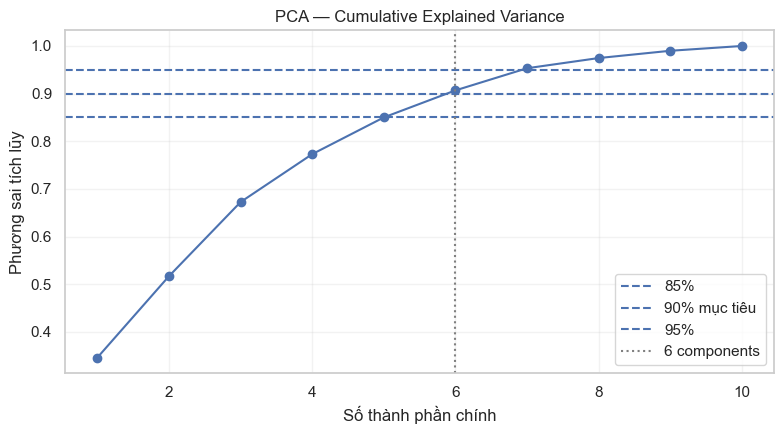

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Imputer và scaler được fit trên dữ liệu dùng cho phân tích PCA.
imputer_pca = SimpleImputer(strategy="median")
scaler_pca = StandardScaler()
X_pca_imputed = imputer_pca.fit_transform(X_all)
X_scaled = scaler_pca.fit_transform(X_pca_imputed)

pca_full = PCA(random_state=RANDOM_STATE)
X_pca_full = pca_full.fit_transform(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
# Chọn số component nhỏ nhất đạt 90%; ngưỡng 90% nằm trong khoảng 85–95% yêu cầu.
n_components = int(np.argmax(cum_var >= 0.90) + 1) if np.any(cum_var >= 0.90) else len(cum_var)
pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Số component được chọn: {n_components}")
print(f"Tổng phương sai giữ lại: {pca.explained_variance_ratio_.sum():.2%}")

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(cum_var)+1), cum_var, marker="o")
plt.axhline(0.85, linestyle="--", label="85%")
plt.axhline(0.90, linestyle="--", label="90% mục tiêu")
plt.axhline(0.95, linestyle="--", label="95%")
plt.axvline(n_components, color="gray", linestyle=":", label=f"{n_components} components")
plt.xlabel("Số thành phần chính")
plt.ylabel("Phương sai tích lũy")
plt.title("PCA — Cumulative Explained Variance")
plt.grid(alpha=.25); plt.legend(); plt.tight_layout(); plt.show()

,PC1,PC2,PC3,PC4,PC5,PC6
year,0.200,0.518,0.157,-0.064,-0.036,0.749
rank_v1,-0.382,0.331,0.248,-0.167,0.157,-0.016
rating_v1,0.413,-0.335,-0.210,0.132,-0.117,0.064
votes_v1,0.473,0.108,-0.175,-0.045,-0.058,0.075
runtime_v1,0.256,-0.223,0.605,-0.013,-0.004,-0.139
votes_2026,0.462,0.154,-0.178,-0.096,0.018,-0.083
runtime_2026,0.219,-0.223,0.642,-0.027,0.021,0.092
metascore,-0.112,-0.509,-0.155,-0.117,0.626,0.494
budget,0.015,0.156,0.066,0.939,0.272,0.012
box_office,0.282,0.302,0.004,-0.205,0.700,-0.389


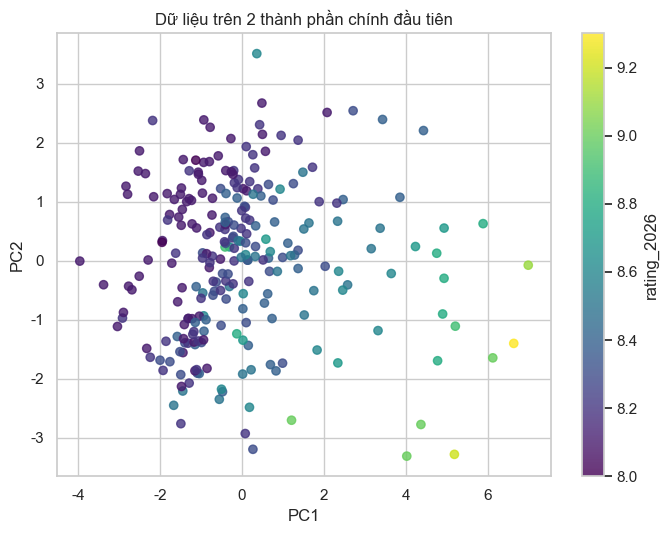

In [17]:
# Output của PCA: ma trận thành phần chính, hệ số tải (loadings) và scatter 2D
loadings = pd.DataFrame(pca.components_.T, index=feature_cols,
                        columns=[f"PC{i+1}" for i in range(n_components)])
display(loadings.round(3))

if n_components >= 2:
    plt.figure(figsize=(7, 5.5))
    sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=model_df["rating_2026"], cmap="viridis", alpha=.8)
    plt.colorbar(sc, label="rating_2026")
    plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Dữ liệu trên 2 thành phần chính đầu tiên")
    plt.tight_layout(); plt.show()

## 7. K-Means — phân cụm và chọn K

,K,WCSS gốc,Silhouette gốc
0,2,1934.672686,0.322273
1,3,1657.267039,0.211287
2,4,1427.181416,0.219187
3,5,1248.245002,0.226511
4,6,1116.506396,0.211262
5,7,1018.018251,0.216740
6,8,935.621795,0.210314


,K,WCSS PCA,Silhouette PCA
0,2,1701.677528,0.346453
1,3,1425.529270,0.239574
2,4,1195.041477,0.253053
3,5,1017.317609,0.260455
4,6,893.471608,0.243547
5,7,810.948363,0.255956
6,8,746.176381,0.242949


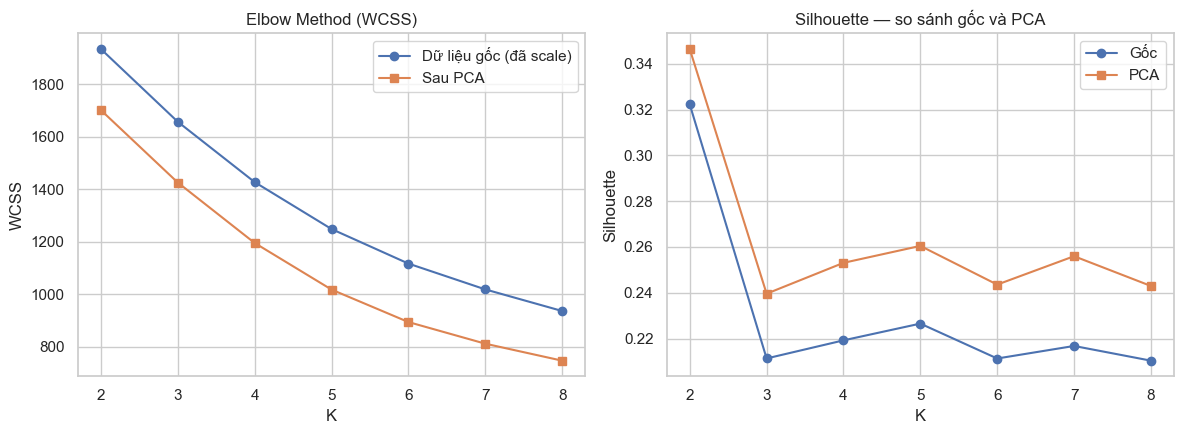

K được chọn theo Silhouette của PCA: 2
Silhouette gốc: 0.3223
Silhouette PCA: 0.3465


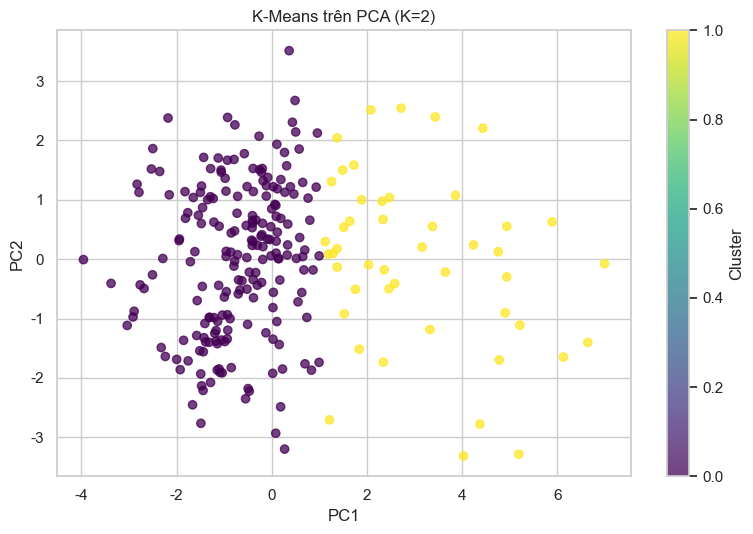

,So_phim,Rating_trung_binh,Rating_trung_vi
Cluster_Label,,,
0,203,8.252,8.2
1,47,8.585,8.5


In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Dùng cùng bộ dữ liệu đã impute/scale để so sánh clustering trước và sau PCA.
k_values = list(range(2, min(8, len(model_df)-1) + 1))
if len(k_values) == 0:
    raise ValueError("Không đủ dòng dữ liệu để chạy K-Means.")

def evaluate_kmeans(X, ks):
    rows = []
    fitted = {}
    for k in ks:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = km.fit_predict(X)
        sil = silhouette_score(X, labels) if len(np.unique(labels)) > 1 else np.nan
        rows.append({"K": k, "WCSS (Inertia)": km.inertia_, "Silhouette": sil})
        fitted[k] = km
    return pd.DataFrame(rows), fitted

metrics_original, models_original = evaluate_kmeans(X_scaled, k_values)
metrics_pca, models_pca = evaluate_kmeans(X_pca, k_values)
display(metrics_original.rename(columns={"WCSS (Inertia)":"WCSS gốc","Silhouette":"Silhouette gốc"}))
display(metrics_pca.rename(columns={"WCSS (Inertia)":"WCSS PCA","Silhouette":"Silhouette PCA"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(metrics_original["K"], metrics_original["WCSS (Inertia)"], marker="o", label="Dữ liệu gốc (đã scale)")
axes[0].plot(metrics_pca["K"], metrics_pca["WCSS (Inertia)"], marker="s", label="Sau PCA")
axes[0].set_title("Elbow Method (WCSS)"); axes[0].set_xlabel("K"); axes[0].set_ylabel("WCSS"); axes[0].legend()
axes[1].plot(metrics_original["K"], metrics_original["Silhouette"], marker="o", label="Gốc")
axes[1].plot(metrics_pca["K"], metrics_pca["Silhouette"], marker="s", label="PCA")
axes[1].set_title("Silhouette — so sánh gốc và PCA"); axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette"); axes[1].legend()
plt.tight_layout(); plt.show()

# Chọn K có Silhouette cao nhất ở không gian PCA; báo cáo cả hai không gian với cùng K.
valid_silhouette = metrics_pca.dropna(subset=["Silhouette"])
if valid_silhouette.empty:
    raise ValueError("Không tính được Silhouette Score. Hãy kiểm tra số dòng và số cụm.")
best_k = int(valid_silhouette.loc[valid_silhouette["Silhouette"].idxmax(), "K"])
kmeans_original = models_original[best_k]
kmeans_pca = models_pca[best_k]
df_clean.loc[model_df.index, "Cluster_Label"] = kmeans_pca.labels_
print(f"K được chọn theo Silhouette của PCA: {best_k}")
print("Silhouette gốc:", round(float(metrics_original.loc[metrics_original.K == best_k, "Silhouette"].iloc[0]), 4))
print("Silhouette PCA:", round(float(metrics_pca.loc[metrics_pca.K == best_k, "Silhouette"].iloc[0]), 4))

if X_pca.shape[1] >= 2:
    plot_xy = X_pca[:, :2]
else:
    plot_xy = np.column_stack([X_pca[:, 0], np.zeros(len(X_pca))])
plt.figure(figsize=(8, 5.5))
plt.scatter(plot_xy[:, 0], plot_xy[:, 1], c=kmeans_pca.labels_, cmap="viridis", alpha=.75)
plt.xlabel("PC1"); plt.ylabel("PC2" if X_pca.shape[1] >= 2 else "(không có PC2)")
plt.title(f"K-Means trên PCA (K={best_k})"); plt.colorbar(label="Cluster"); plt.tight_layout(); plt.show()

cluster_summary = model_df[["rating_2026"]].copy()
cluster_summary["Cluster_Label"] = kmeans_pca.labels_
display(cluster_summary.groupby("Cluster_Label").agg(
    So_phim=("rating_2026","size"),
    Rating_trung_binh=("rating_2026","mean"),
    Rating_trung_vi=("rating_2026","median")
).round(3))

In [19]:
# So sánh khả năng diễn giải: mô tả cụm bằng CÁC BIẾN GỐC (PCA khó diễn giải hơn vì mỗi PC trộn nhiều biến)
profile = X_all.copy()
profile["Cluster"] = kmeans_pca.labels_
display(profile.groupby("Cluster").agg(["median"]).droplevel(1, axis=1).round(2)
        .join(profile.groupby("Cluster").size().rename("So_phim")))

# Mức đồng thuận giữa cụm trên dữ liệu gốc và cụm trên PCA
from sklearn.metrics import adjusted_rand_score
print("Adjusted Rand Index (cụm gốc vs cụm PCA):",
      round(adjusted_rand_score(kmeans_original.labels_, kmeans_pca.labels_), 3))

,year,rank_v1,rating_v1,votes_v1,runtime_v1,votes_2026,runtime_2026,metascore,budget,box_office,So_phim
Cluster,,,,,,,,,,,
0,1995.0,146.0,8.2,466863.0,122.0,461004.0,124.0,85.0,13500000.0,46039729.0,203
1,2000.0,36.0,8.5,1266092.0,146.0,1595817.0,146.0,78.0,63000000.0,383336762.0,47


Adjusted Rand Index (cụm gốc vs cụm PCA): 1.0


**Nhận xét chọn K và so sánh PCA:** K = 2 được chọn theo Silhouette cao nhất (PCA 0.346; gốc 0.322). Đường WCSS giảm đều, không có khuỷu rõ rệt nên Elbow không xác nhận độc lập K = 2. Silhouette ở hai không gian khác nhau nên không so sánh trực tiếp; chỉ số đáng tin hơn là Adjusted Rand Index (= 1.0 ở lần chạy trước), tức PCA và không PCA cho cùng một cách chia cụm. Lợi ích của PCA ở đây là giảm chiều (10 → 6) và trực quan hóa 2D.

## 8. Supervised Learning — Regression

Mô hình: **Linear Regression** (tham số trọng số W và bias b) và **Decision Tree Regressor** (chia nút theo mức giảm phương sai). Chỉ số: MSE, RMSE, R² (thêm MAE).

,Mô hình,MAE,MSE,RMSE,R²
1,Decision Tree Regressor,0.0634,0.0142,0.1193,0.6143
0,Linear Regression,0.0692,0.0153,0.1235,0.5864


Mô hình hồi quy tốt nhất theo RMSE thấp nhất: Decision Tree Regressor


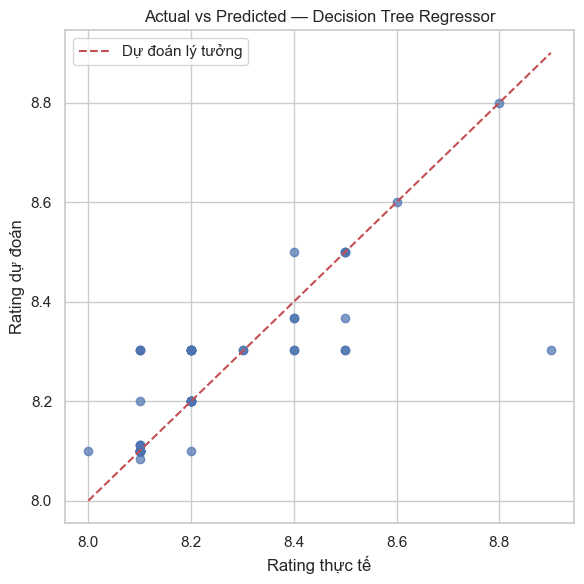

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_all, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

def make_regression_pipeline(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

reg_models = {
    "Linear Regression": make_regression_pipeline(LinearRegression(), scale=True),
    "Decision Tree Regressor": make_regression_pipeline(
        DecisionTreeRegressor(max_depth=5, min_samples_leaf=2, random_state=RANDOM_STATE)
    )
}
reg_rows, reg_predictions = [], {}
for name, model in reg_models.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    reg_predictions[name] = pred
    reg_rows.append({
        "Mô hình": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "MSE": mean_squared_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R²": r2_score(yr_test, pred)
    })
reg_results = pd.DataFrame(reg_rows).sort_values(["RMSE", "MAE"])
display(reg_results.round(4))
best_reg_name = reg_results.iloc[0]["Mô hình"]
best_reg_model = reg_models[best_reg_name]
print("Mô hình hồi quy tốt nhất theo RMSE thấp nhất:", best_reg_name)

best_pred = reg_predictions[best_reg_name]
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, best_pred, alpha=.7)
lims = [min(yr_test.min(), best_pred.min()), max(yr_test.max(), best_pred.max())]
plt.plot(lims, lims, "r--", label="Dự đoán lý tưởng")
plt.xlabel("Rating thực tế"); plt.ylabel("Rating dự đoán")
plt.title(f"Actual vs Predicted — {best_reg_name}"); plt.legend(); plt.tight_layout(); plt.show()

,Feature,Weight (W)
0,rating_v1,0.1635
1,votes_2026,0.0697
2,runtime_2026,0.0544
3,runtime_v1,-0.0306
4,rank_v1,-0.0275
5,votes_v1,-0.0259
6,box_office,-0.0199
7,budget,0.0153
8,metascore,0.0079
9,year,-0.0016


Bias (b) = 8.3295


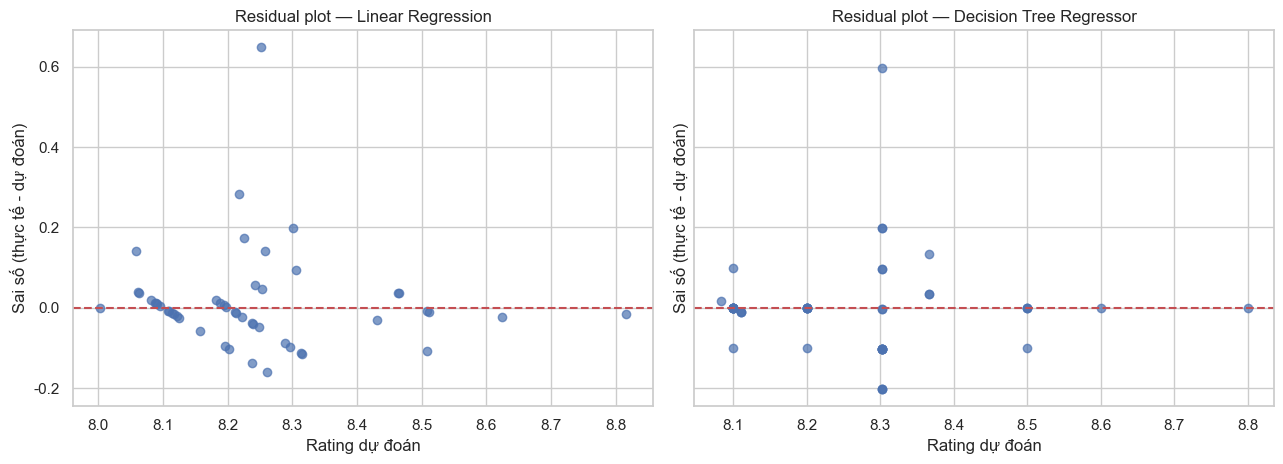

In [21]:
# Linear Regression: trọng số W (trên dữ liệu đã chuẩn hóa) và bias b
lin = reg_models["Linear Regression"].named_steps["model"]
weights = (pd.DataFrame({"Feature": feature_cols, "Weight (W)": lin.coef_})
             .iloc[np.argsort(-np.abs(lin.coef_))].reset_index(drop=True))
display(weights.round(4))
print(f"Bias (b) = {lin.intercept_:.4f}")

# Residual plot: kiểm tra heteroscedasticity hoặc cấu trúc trong sai số
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (name, pred) in zip(axes, reg_predictions.items()):
    resid = yr_test.to_numpy() - pred
    ax.scatter(pred, resid, alpha=.7)
    ax.axhline(0, color="r", linestyle="--")
    ax.set_title(f"Residual plot — {name}")
    ax.set_xlabel("Rating dự đoán"); ax.set_ylabel("Sai số (thực tế - dự đoán)")
plt.tight_layout(); plt.show()

**Cách đọc residual plot:** sai số nên rải đều quanh 0. Nếu độ rộng của đám điểm thay đổi theo giá trị dự đoán (hình phễu) là dấu hiệu **heteroscedasticity**; nếu có đường cong rõ rệt là mô hình bỏ sót cấu trúc phi tuyến.

### 8.3 Baseline và cross-validation
Mục 0 đặt baseline `ŷ = rating_v1` nhưng chưa tính. Tập test chỉ có 50 phim và hai mô hình chênh rất ít, nên thêm baseline và 5-fold CV để kết luận mô hình thắng có cơ sở hơn. Baseline chỉ tính được trên các phim có `rating_v1`.

In [22]:
from sklearn.model_selection import cross_val_score, KFold

mask = Xr_test["rating_v1"].notna()
base_pred = Xr_test.loc[mask, "rating_v1"]
base_true = yr_test[mask]
print(f"Baseline ŷ = rating_v1 (chỉ {mask.sum()}/{len(Xr_test)} phim test có rating_v1): "
      f"RMSE = {np.sqrt(mean_squared_error(base_true, base_pred)):.4f} | "
      f"R² = {r2_score(base_true, base_pred):.4f}")
for name in ["Linear Regression", "Decision Tree Regressor"]:
    p = reg_models[name].predict(Xr_test[mask])
    print(f"{name} trên cùng {mask.sum()} phim: RMSE = {np.sqrt(mean_squared_error(base_true, p)):.4f}")

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, m in reg_models.items():
    s = cross_val_score(m, X_all, y_reg, cv=kf, scoring="neg_root_mean_squared_error")
    print(f"{name}: RMSE 5-fold = {-s.mean():.4f} ± {s.std():.4f}")


Baseline ŷ = rating_v1 (chỉ 37/50 phim test có rating_v1): RMSE = 0.0435 | R² = 0.9395
Linear Regression trên cùng 37 phim: RMSE = 0.0530
Decision Tree Regressor trên cùng 37 phim: RMSE = 0.0527
Linear Regression: RMSE 5-fold = 0.1221 ± 0.0090
Decision Tree Regressor: RMSE 5-fold = 0.1224 ± 0.0193


## 9. Supervised Learning — Classification

**Quy trình 5 bước theo mẫu thực hành của cô:** (1) chuẩn bị dữ liệu, chọn X và y, (2) chia train/test, (3) chọn mô hình, (4) huấn luyện và dự đoán, (5) đánh giá.

Mô hình: **Logistic Regression** (với 3 lớp, sklearn dùng dạng mở rộng của hàm Sigmoid cho nhiều lớp) và **Decision Tree Classifier** (chia nút để tối đa information gain, tức giảm Gini hoặc Entropy). Chỉ số: Confusion Matrix, Precision, Recall, Accuracy, F1-score.

**Lưu ý:** `rating_2026` có nhiều giá trị trùng nhau (median = 8.2). Cách chia tertiles bằng `rank(method="first")` ở bản trước đã xếp các phim cùng rating vào nhóm khác nhau theo thứ tự dòng (nhãn nhiễu), nên nay đổi sang **ngưỡng rating cố định** để phim cùng điểm luôn cùng nhóm. Vì các nhóm không còn đều nhau, cần kiểm tra mất cân bằng lớp và dùng `class_weight='balanced'`. **Kết quả phân loại phải chạy lại và cập nhật vào báo cáo.**

Phân bố nhãn mục tiêu:


,Số phim
Nhóm rating,
Trung bình,90
Cao,88
Thấp,72


Tỷ lệ (%): {'Trung bình': 36.0, 'Cao': 35.2, 'Thấp': 28.8}


,Mô hình,Accuracy,F1-macro,F1-weighted
0,Logistic Regression,0.76,0.7673,0.7570
1,Decision Tree Classifier,0.72,0.7315,0.7215


Mô hình tốt nhất theo F1-macro: Logistic Regression

Báo cáo phân loại:
              precision    recall  f1-score   support

         Cao       0.79      0.61      0.69        18
        Thấp       0.87      0.93      0.90        14
  Trung bình       0.67      0.78      0.72        18

    accuracy                           0.76        50
   macro avg       0.77      0.77      0.77        50
weighted avg       0.77      0.76      0.76        50



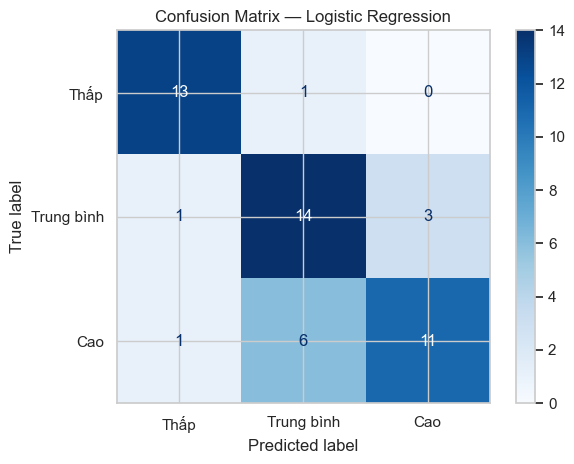

In [23]:
# BƯỚC 1: Chuẩn bị dữ liệu, chọn features (X) và nhãn (y)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)

# IMDb Top 250 có rating cao, nên ngưỡng cố định 7 và 8 có thể
# làm toàn bộ dữ liệu rơi vào một lớp "Cao".
# Theo mẫu thực hành của cô, mô hình phân loại cần có nhãn y gồm >= 2 lớp.
# Chia rating thành 3 nhóm theo ngưỡng cố định (phim cùng rating luôn cùng nhóm):
# Thấp <= 8.1 | Trung bình 8.2-8.3 | Cao >= 8.4
y_class = pd.cut(
    y_reg,
    bins=[-np.inf, 8.15, 8.35, np.inf],
    labels=["Thấp", "Trung bình", "Cao"]
)

# Kiểm tra mất cân bằng lớp (yêu cầu Imbalance Handling)
print("Phân bố nhãn mục tiêu:")
display(y_class.value_counts().rename_axis("Nhóm rating").to_frame("Số phim"))
print("Tỷ lệ (%):", (y_class.value_counts(normalize=True) * 100).round(1).to_dict())

# BƯỚC 2: Chia dữ liệu thành tập huấn luyện và tập kiểm tra
class_counts = y_class.value_counts()
if len(class_counts) < 2:
    raise ValueError(
        "Dữ liệu chỉ có một lớp. Hãy kiểm tra lại cách tạo nhãn y_class."
    )
if class_counts.min() < 2:
    raise ValueError(
        "Có lớp có dưới 2 mẫu, không thể chia train/test ổn định. "
        "Cần thêm dữ liệu hoặc gộp các lớp quá ít mẫu."
    )

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_all,
    y_class,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_class
)

# BƯỚC 3: Lựa chọn mô hình phân loại
class_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced"
        ))
    ]),
    "Decision Tree Classifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

# BƯỚC 4: Huấn luyện và dự đoán trên tập test
class_rows = []
class_preds = {}

for name, model in class_models.items():
    model.fit(Xc_train, yc_train)
    y_pred = model.predict(Xc_test)
    class_preds[name] = y_pred

    class_rows.append({
        "Mô hình": name,
        "Accuracy": accuracy_score(yc_test, y_pred),
        "F1-macro": f1_score(
            yc_test, y_pred, average="macro", zero_division=0
        ),
        "F1-weighted": f1_score(
            yc_test, y_pred, average="weighted", zero_division=0
        )
    })

# BƯỚC 5: Đánh giá mô hình
class_results = pd.DataFrame(class_rows).sort_values(
    "F1-macro", ascending=False
)
display(class_results.round(4))

best_class_name = class_results.iloc[0]["Mô hình"]
best_class_model = class_models[best_class_name]
best_class_pred = class_preds[best_class_name]

print("Mô hình tốt nhất theo F1-macro:", best_class_name)
print("\nBáo cáo phân loại:")
print(classification_report(
    yc_test, best_class_pred, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    yc_test,
    best_class_pred,
    labels=["Thấp", "Trung bình", "Cao"],
    cmap="Blues",
    values_format="d"
)
plt.title(f"Confusion Matrix — {best_class_name}")
plt.tight_layout()
plt.show()

Logistic Regression
              precision    recall  f1-score   support

         Cao       0.79      0.61      0.69        18
        Thấp       0.87      0.93      0.90        14
  Trung bình       0.67      0.78      0.72        18

    accuracy                           0.76        50
   macro avg       0.77      0.77      0.77        50
weighted avg       0.77      0.76      0.76        50

Decision Tree Classifier
              precision    recall  f1-score   support

         Cao       0.79      0.61      0.69        18
        Thấp       0.86      0.86      0.86        14
  Trung bình       0.59      0.72      0.65        18

    accuracy                           0.72        50
   macro avg       0.74      0.73      0.73        50
weighted avg       0.74      0.72      0.72        50



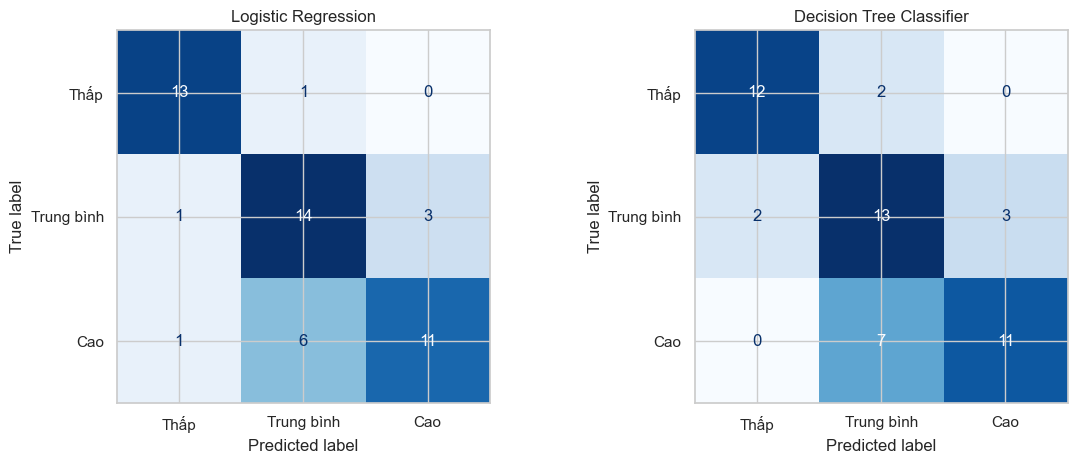

,criterion,Accuracy,F1-macro
0,gini,0.72,0.7315
1,entropy,0.68,0.6747


In [24]:
# Báo cáo và confusion matrix cho CẢ HAI mô hình
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, pred) in zip(axes, class_preds.items()):
    print("=" * 60); print(name); print(classification_report(yc_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(yc_test, pred, labels=["Thấp", "Trung bình", "Cao"],
                                            cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

# Gini và Entropy cho Decision Tree
crit_rows = []
for crit in ["gini", "entropy"]:
    m = Pipeline([("imputer", SimpleImputer(strategy="median")),
                  ("model", DecisionTreeClassifier(criterion=crit, max_depth=5, min_samples_leaf=2,
                                                   class_weight="balanced", random_state=RANDOM_STATE))])
    m.fit(Xc_train, yc_train)
    p = m.predict(Xc_test)
    crit_rows.append({"criterion": crit, "Accuracy": accuracy_score(yc_test, p),
                      "F1-macro": f1_score(yc_test, p, average="macro", zero_division=0)})
display(pd.DataFrame(crit_rows).round(4))

## 10. Tổng kết đánh giá và khuyến nghị

In [25]:
print("=== TÓM TẮT KẾT QUẢ ===")
print(f"PCA: {n_components} thành phần giữ {pca.explained_variance_ratio_.sum():.2%} phương sai.")
print(f"K-Means: K={best_k}; Silhouette gốc={metrics_original.loc[metrics_original.K == best_k, 'Silhouette'].iloc[0]:.4f}; Silhouette PCA={metrics_pca.loc[metrics_pca.K == best_k, 'Silhouette'].iloc[0]:.4f}.")
print(f"Hồi quy tốt nhất theo RMSE: {best_reg_name}.")
print(f"Phân loại tốt nhất theo F1-macro: {best_class_name}.")

print("\nKhuyến nghị kinh doanh cần được chốt dựa trên kết quả thực tế:")
print("1. Dùng phân cụm để xác định nhóm phim có mức rating và đặc trưng tương đồng; xem bảng cluster_summary để mô tả từng nhóm.")
print("2. Dùng mô hình hồi quy tốt nhất để tham khảo rating dự đoán trước khi ưu tiên phân tích phim; không xem dự đoán là đánh giá chắc chắn.")
print("3. Theo dõi F1-macro và confusion matrix của mô hình phân loại; nếu nhóm rating thấp/trung bình/cao bị nhầm nhiều, cần xem lại dữ liệu và ngưỡng phân nhóm.")

=== TÓM TẮT KẾT QUẢ ===
PCA: 6 thành phần giữ 90.68% phương sai.
K-Means: K=2; Silhouette gốc=0.3223; Silhouette PCA=0.3465.
Hồi quy tốt nhất theo RMSE: Decision Tree Regressor.
Phân loại tốt nhất theo F1-macro: Logistic Regression.

Khuyến nghị kinh doanh cần được chốt dựa trên kết quả thực tế:
1. Dùng phân cụm để xác định nhóm phim có mức rating và đặc trưng tương đồng; xem bảng cluster_summary để mô tả từng nhóm.
2. Dùng mô hình hồi quy tốt nhất để tham khảo rating dự đoán trước khi ưu tiên phân tích phim; không xem dự đoán là đánh giá chắc chắn.
3. Theo dõi F1-macro và confusion matrix của mô hình phân loại; nếu nhóm rating thấp/trung bình/cao bị nhầm nhiều, cần xem lại dữ liệu và ngưỡng phân nhóm.


## 11. Chuẩn bị mô hình cho giao diện Streamlit
Cell này lưu mô hình hồi quy/phân loại tốt nhất cùng tiền xử lý. Chạy xong sẽ tạo `stage2_models.joblib`. File giao diện `app_stage2.py` được cung cấp riêng cùng notebook.

In [26]:
import joblib
artifact = {
    "feature_cols": feature_cols,
    "feature_defaults": model_df[feature_cols].median().fillna(0).to_dict(),
    "regression_model": best_reg_model,
    "regression_model_name": best_reg_name,
    "classification_model": best_class_model,
    "classification_model_name": best_class_name,
    "cluster_imputer": imputer_pca,
    "cluster_scaler": scaler_pca,
    "pca": pca,
    "kmeans_pca": kmeans_pca,
    "rating_tier_rule": "3 nhóm theo ngưỡng rating_2026: Thấp <= 8.1, Trung bình 8.2-8.3, Cao >= 8.4",
    # dữ liệu vẽ biểu đồ PCA / K-Means trong tab Visualization của Streamlit
    "viz": {
        "cum_var": cum_var.tolist(),
        "X_pca_2d": X_pca[:, :2].tolist(),
        "labels": kmeans_pca.labels_.tolist(),
        "rating": model_df["rating_2026"].tolist()
    }
}
joblib.dump(artifact, "stage2_models.joblib")
print("Đã lưu stage2_models.joblib")

Đã lưu stage2_models.joblib


### 12. Xuất dataset có `Cluster_Label`
File `imdb_top250_clean.csv` ở mục 4.7 được lưu trước khi tạo cụm nên chưa có cột `Cluster_Label` (yêu cầu Task 2). Cell dưới lưu bản đầy đủ.

In [27]:
df_clean.to_csv("imdb_top250_clean_with_clusters.csv", index=False)
print(df_clean["Cluster_Label"].value_counts(dropna=False))


Cluster_Label
0.0    203
1.0     47
Name: count, dtype: int64


### Chạy giao diện
Đặt `app_stage2.py` và `stage2_models.joblib` trong cùng thư mục, sau đó chạy ở Terminal:

```bash
pip install streamlit joblib scikit-learn pandas numpy
streamlit run app_stage2.py
```

Giao diện cho phép nhập các thuộc tính số, xem rating dự đoán, nhóm rating dự đoán và cụm K-Means. Chụp ảnh màn hình giao diện sau khi chạy để đưa vào báo cáo Stage 2.